In [ ]:
!pip install mp-api pymatgen matplotlib numpy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.6/55.6 kB 1.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 157.5/157.5 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 825.8/825.8 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.6/41.6 MB 11.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.0/4.0 MB 19.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.6/62.6 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.6/4.6 MB 20.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 20.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 22.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 332.3/332.3 kB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━

In [ ]:
%%writefile mp_xrd_pipeline.py
#!/usr/bin/env python3
"""
mp_xrd_pipeline.py
==================
Mine crystallographic data from the Materials Project (MP) and simulate a
powder X-ray diffraction (XRD) pattern.
"""

from __future__ import annotations

import argparse
import logging
import os
import sys
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
from mp_api.client import MPRester
from pymatgen.analysis.diffraction.xrd import DiffractionPattern, XRDCalculator
from pymatgen.core import Structure
from pymatgen.symmetry.analyzer import SpacegroupAnalyzer

logger = logging.getLogger(__name__)

API_KEY_ENV_VAR = "MP_API_KEY"

SUMMARY_FIELDS = [
    "material_id",
    "formula_pretty",
    "energy_above_hull",
    "volume",
    "density",
    "symmetry",
    "structure",
]

@dataclass
class MaterialRecord:
    material_id: str
    formula: str
    energy_above_hull: float
    volume: float
    density: float
    space_group_symbol: str
    space_group_number: int
    crystal_system: str
    structure: Structure

def get_api_key(cli_key: str | None = None) -> str:
    key = cli_key or os.environ.get(API_KEY_ENV_VAR)
    if not key:
        sys.exit("ERROR: No API key found.")
    return key

def fetch_most_stable_polymorph(api_key: str, formula: str) -> MaterialRecord:
    with MPRester(api_key) as mpr:
        docs = mpr.materials.summary.search(formula=formula, fields=SUMMARY_FIELDS)

    if not docs:
        raise LookupError(f"No entries found in Materials Project for formula '{formula}'.")
    best = min(docs, key=lambda d: d.energy_above_hull)

    return MaterialRecord(
        material_id=str(best.material_id),
        formula=best.formula_pretty,
        energy_above_hull=float(best.energy_above_hull),
        volume=float(best.volume),
        density=float(best.density),
        space_group_symbol=best.symmetry.symbol,
        space_group_number=int(best.symmetry.number),
        crystal_system=str(best.symmetry.crystal_system),
        structure=best.structure,
    )

def print_crystallographic_summary(record: MaterialRecord) -> Structure:
    sga = SpacegroupAnalyzer(record.structure, symprec=0.01)
    conv = sga.get_conventional_standard_structure()
    prim_lat = record.structure.lattice
    conv_lat = conv.lattice

    line = "=" * 64
    print(line)
    print(f" Materials Project entry : {record.material_id}")
    print(f" Formula                 : {record.formula}")
    print(f" Energy above hull       : {record.energy_above_hull:.4f} eV/atom")
    print(line)
    print(f" Space group             : {record.space_group_symbol} (No. {record.space_group_number})")
    print(f" Crystal system          : {record.crystal_system}")
    print(f" Volume (MP cell)        : {record.volume:.4f} Å^3")
    print(f" Volume (conventional)   : {conv_lat.volume:.4f} Å^3")
    print(f" Density                 : {record.density:.4f} g/cm^3")
    print(line)

    def _print_lattice(title: str, lat) -> None:
        a, b, c = lat.abc
        alpha, beta, gamma = lat.angles
        print(f" {title}")
        print(f"   a = {a:.6f} Å   b = {b:.6f} Å   c = {c:.6f} Å")
        print(f"   α = {alpha:.4f}°   β = {beta:.4f}°   γ = {gamma:.4f}°")

    _print_lattice("Lattice parameters (conventional standard cell):", conv_lat)
    _print_lattice("Lattice parameters (primitive cell, as stored in MP):", prim_lat)
    print(line)
    return conv

def simulate_xrd(
    structure: Structure,
    wavelength: str = "CuKa",
    two_theta_range: tuple[float, float] = (10.0, 90.0),
) -> DiffractionPattern:
    calculator = XRDCalculator(wavelength=wavelength)
    pattern = calculator.get_pattern(
        structure, scaled=True, two_theta_range=two_theta_range
    )
    return pattern

def _format_hkl(hkl: tuple[int, ...]) -> str:
    parts = [rf"\bar{{{abs(i)}}}" if i < 0 else str(i) for i in hkl]
    return r"$(" + r"\,".join(parts) + r")$"

def _peak_label(hkls: list[dict], max_families: int = 2) -> str:
    labels = [_format_hkl(h["hkl"]) for h in hkls[:max_families]]
    label = ", ".join(labels)
    if len(hkls) > max_families:
        label += " …"
    return label

def plot_xrd(
    pattern: DiffractionPattern,
    title: str,
    output_path: str = "xrd_pattern.png",
    n_labels: int = 3,
    show: bool = True,
) -> None:
    two_theta = np.asarray(pattern.x)
    intensity = np.asarray(pattern.y)

    plt.rcParams.update({
        "font.family": "serif",
        "mathtext.fontset": "dejavuserif",
        "font.size": 12,
        "axes.linewidth": 1.2,
        "xtick.direction": "in",
        "ytick.direction": "in",
        "xtick.top": True,
        "ytick.right": True,
        "xtick.major.width": 1.2,
        "ytick.major.width": 1.2,
    })

    fig, ax = plt.subplots(figsize=(7, 4.5), dpi=150)
    ax.vlines(two_theta, 0, intensity, color="#1f3b73", linewidth=1.6)

    top_idx = np.argsort(intensity)[::-1][:n_labels]
    for i in top_idx:
        ax.annotate(
            _peak_label(pattern.hkls[i]),
            xy=(two_theta[i], intensity[i]),
            xytext=(0, 6),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=11,
            color="#b22222",
        )

    ax.set_xlabel(r"$2\theta$ (degrees)")
    ax.set_ylabel("Relative intensity (a.u.)")
    ax.set_title(title, pad=10)
    ax.set_xlim(two_theta.min() - 2, two_theta.max() + 2)
    ax.set_ylim(0, 118)
    ax.set_yticks(np.arange(0, 101, 20))

    fig.tight_layout()
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    if show:
        plt.show()
    plt.close(fig)

def print_top_peaks(pattern: DiffractionPattern, n: int = 3) -> None:
    print(f" Top {n} XRD reflections (Cu-Kα)")
    print(f"   {'2θ (°)':>9} {'d (Å)':>9} {'I_rel':>8}   hkl")
    for i in np.argsort(pattern.y)[::-1][:n]:
        hkls = ", ".join(str(h["hkl"]) for h in pattern.hkls[i])
        print(f"   {pattern.x[i]:9.3f} {pattern.d_hkls[i]:9.4f} {pattern.y[i]:8.2f}   {hkls}")
    print("=" * 64)

def parse_args() -> argparse.Namespace:
    parser = argparse.ArgumentParser()
    parser.add_argument("-f", "--formula", default="Ti")
    parser.add_argument("--api-key", default=None)
    parser.add_argument("--two-theta-range", nargs=2, type=float, default=(10.0, 90.0))
    parser.add_argument("-o", "--output", default=None)
    parser.add_argument("--no-show", action="store_true")
    parser.add_argument("-v", "--verbose", action="store_true")
    return parser.parse_args()

def main() -> None:
    args = parse_args()
    logging.basicConfig(level=logging.INFO if args.verbose else logging.WARNING)
    api_key = get_api_key(args.api_key)
    try:
        record = fetch_most_stable_polymorph(api_key, args.formula)
    except LookupError as err:
        sys.exit(f"ERROR: {err}")

    conv_structure = print_crystallographic_summary(record)
    pattern = simulate_xrd(conv_structure, two_theta_range=tuple(args.two_theta_range))
    print_top_peaks(pattern, n=3)

    output = args.output or f"{record.formula}_{record.material_id}_xrd.png"
    title = f"Simulated XRD (Cu-K$\\alpha$): {record.formula}, {record.space_group_symbol} ({record.material_id})"
    plot_xrd(pattern, title, output_path=output, show=not args.no_show)

if __name__ == "__main__":
    main()


Overwriting mp_xrd_pipeline.py


In [ ]:
!python mp_xrd_pipeline.py --formula Fe --api-key vVEek8zdNvrohbmFWcr1sHZM1cB3aUCa

Retrieving SummaryDoc documents: 100% 10/10 [00:00<00:00, 131896.35it/s]
 Materials Project entry : mp-13
 Formula                 : Fe
 Energy above hull       : 0.0000 eV/atom
 Space group             : Im-3m (No. 229)
 Crystal system          : Cubic
 Volume (MP cell)        : 23.4682 Å^3
 Volume (conventional)   : 23.4682 Å^3
 Density                 : 7.9029 g/cm^3
 Lattice parameters (conventional standard cell):
   a = 2.863035 Å   b = 2.863035 Å   c = 2.863035 Å
   α = 90.0000°   β = 90.0000°   γ = 90.0000°
 Lattice parameters (primitive cell, as stored in MP):
   a = 2.477813 Å   b = 2.477809 Å   c = 4.054295 Å
   α = 90.0000°   β = 90.0003°   γ = 109.4698°
 Top 3 XRD reflections (Cu-Kα)
      2θ (°)     d (Å)    I_rel   hkl
      44.767    2.0245   100.00   (1, 1, 0)
      82.534    1.1688    28.50   (2, 1, 1)
      65.168    1.4315    14.68   (2, 0, 0)
Figure(1050x675)


Here is your graph: Fe_mp-13_xrd.png


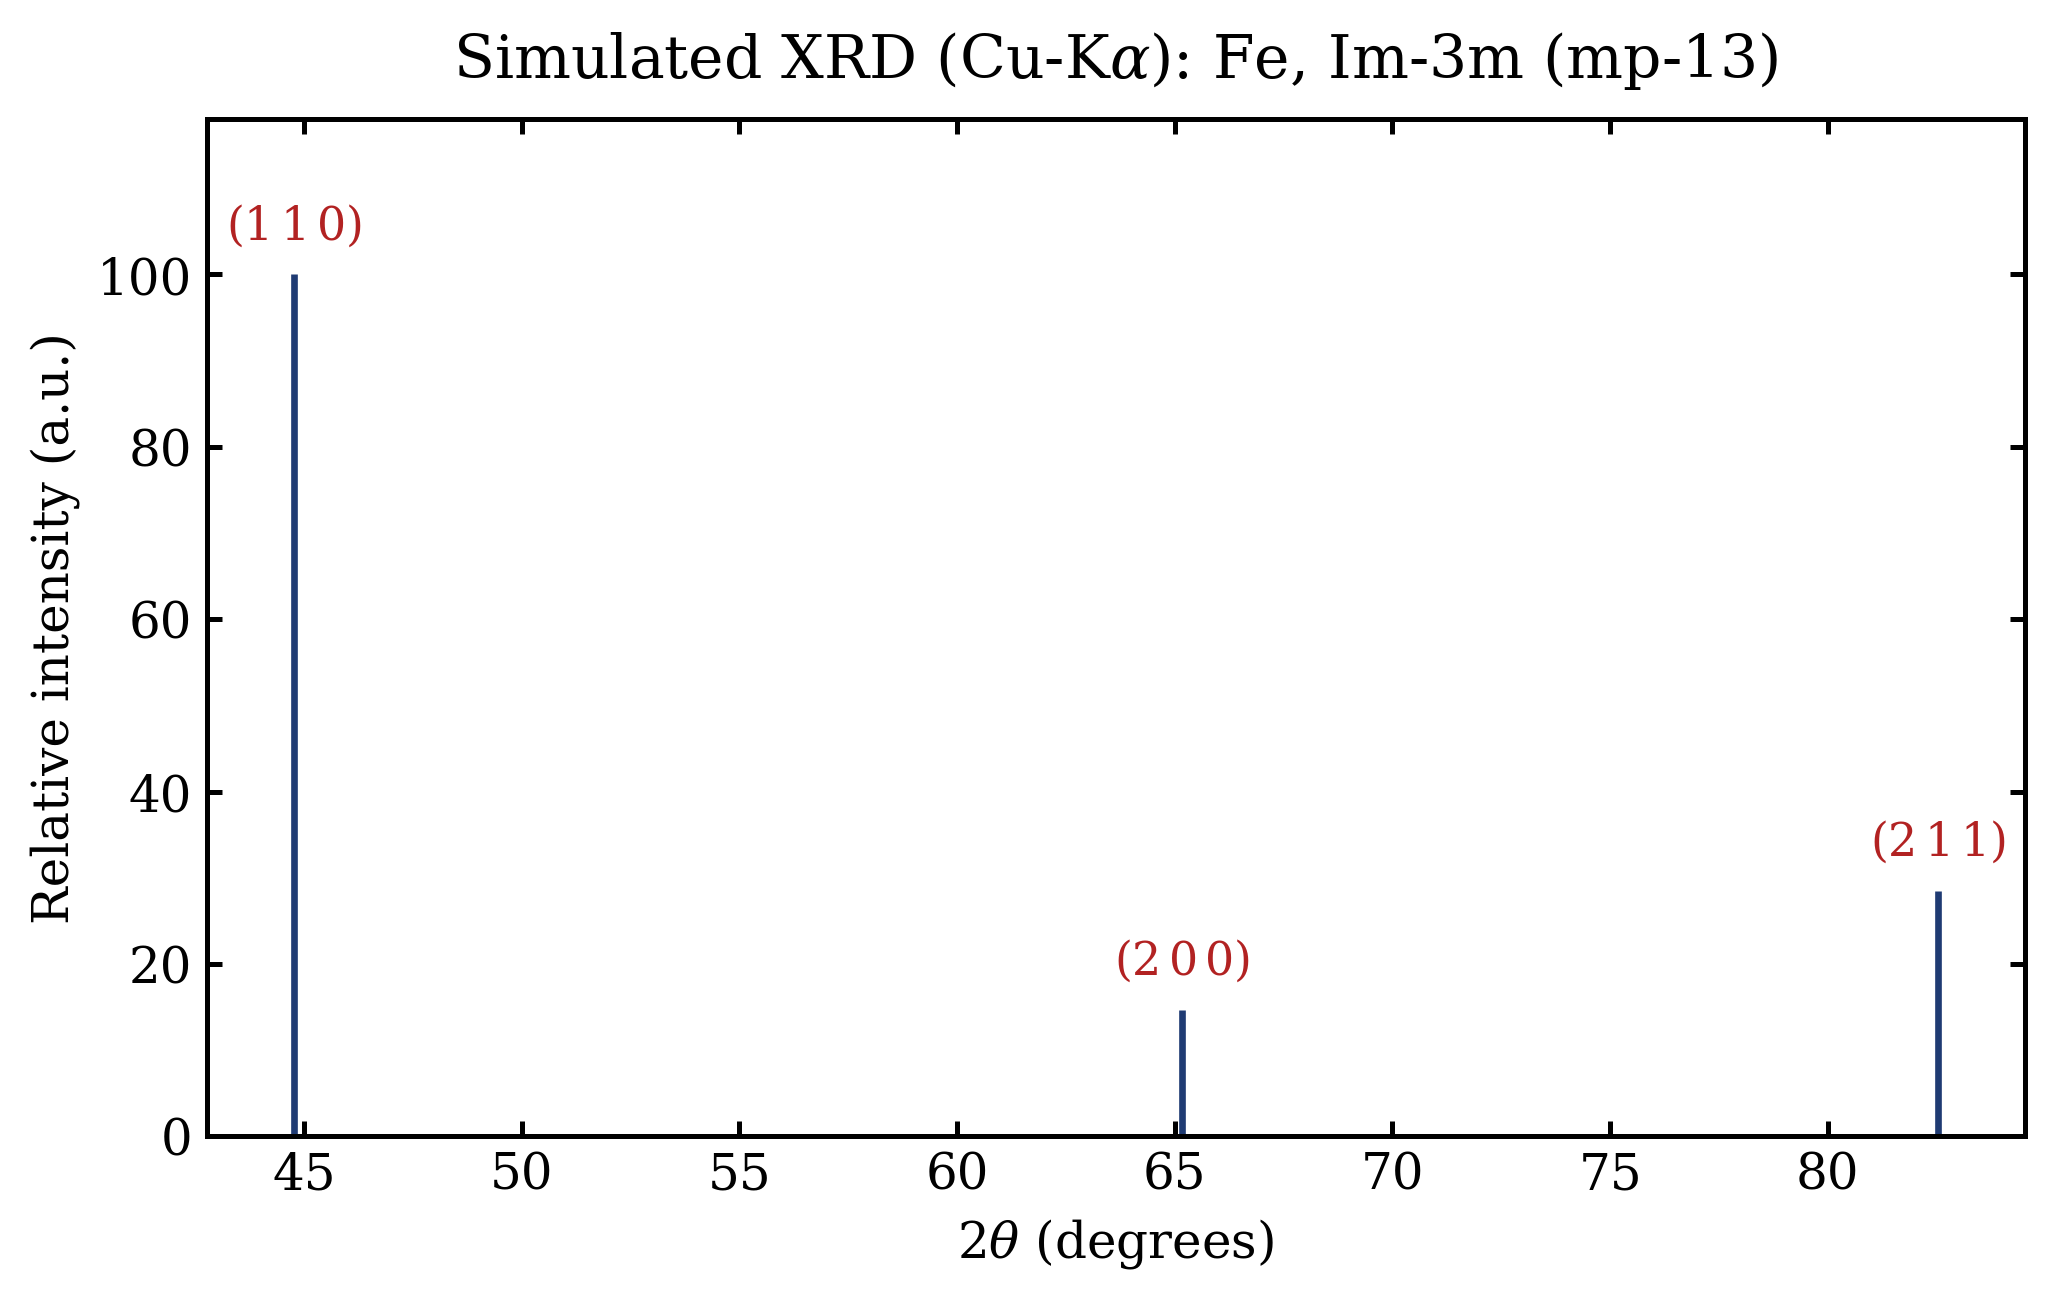

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from IPython.display import Image, display
from google.colab import files
import glob

# Find the generated PNG image
images = glob.glob("*_xrd.png")

if images:
    for img in images:
        print(f"Here is your graph: {img}")
        display(Image(filename=img)) # Shows the image on screen
        files.download(img)          # Downloads it to your computer
else:
    print("No image found. The script might not have saved it properly.")